# 01 · Quality control — GSE216146

Builds the AnnData from the GEO counts files (sparse UMI matrix + gene list + cell metadata), keeps the six selected
samples (3 control `PN`, 3 chemotherapy `CN`), computes QC metrics from the raw counts, filters cells per sample and
genes after merging, then normalizes.

**Input** (in `$DATA`): `GSE216146_expression_matrix.mtx.gz` (cells x genes, integer counts),
`GSE216146_genes.tsv.gz`, `GSE216146_cell_metadata.tsv.gz` · **Output:** `results/01_qc.h5ad` (raw counts in
`layers["counts"]`, log-normalized `X`), QC plots in `results/plots/`, cell counts in `results/tables/01_qc_cell_counts.tsv`.

Notes on the input (checked on 2026-11-13):
- The mtx holds 19,834 cells x 32,285 genes; its rows follow the metadata order and its columns the gene list.
  It is identical to `raw.X` of the authors' h5ad (which is not used here).
- The cells were already filtered by the authors (≥ 500 genes, ribo < 25 %) and Scrublet doublets removed
  (`predicted_doublet` is all `False`). Only a few author columns are kept in `obs` (`qc.metadata_columns`);
  the author QC columns are dropped because QC is recomputed here.
- The authors' `pct_mt` (max 7 %) was computed on a matrix where `mt-` genes have zero counts, so their mitochondrial
  filter had no effect. Recomputed on the counts, the D20 batch has a much higher mt fraction (median ~11–14 % vs ~4–5 % in D21).
  A fixed 20 % cut would remove ~1/3 of the D20 cells, so the mt filter is **per sample: median + 3 MAD**.
- Mouse mitochondrial genes start with lower-case `mt-` (the original script used `Mt-`, which matched nothing).
- `pathology` has four codes (`PN`, `PS`, `CN`, `CS`); only `PN` and `CN` samples are analysed here.

> **Known QC bias (checked 2026-11-13, QC kept as is by decision; see the "QC bias check" section below):**
> - The per-sample mt cut is set by the glia-dominated distribution, so it **removes many neurons** (46 % in
>   controls, 62 % in cisplatin; 86–92 % in the D21 cisplatin samples). Before QC, neuron proportions barely
>   differ between conditions, so any downstream neuron decrease is mostly a QC effect.
> - Neuroblasts are already lower in every cisplatin sample **before QC** (0.2–0.6 % vs 1.4–1.8 %): not a QC effect.
> - The ribo > 20 % filter removes **more microglia after cisplatin** (9.4 % vs 3.5 % of microglia). The removed
>   microglia are not more activated (DAM score similar), but the filter trims the high-ribosomal tail that is up
>   in cisplatin microglia (06), so that effect is under- rather than over-estimated.
> - Oligodendrocytes lose ~35–39 % in D20 vs 4–6 % in D21 (mt): a batch effect, absorbed by `~ batch + condition`.

In [1]:
import gc
from importlib.metadata import version
import sys
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import sc_utils as scu

cfg = scu.load_config(ROOT / "config.yaml")
qc = cfg["qc"]
samples = cfg["samples"]
scu.setup_plotting()
print("scanpy", version("scanpy"), "| anndata", version("anndata"))
print("samples:", samples)

scanpy 1.12.5 | anndata 0.13.4
samples: {'D20-6407': 'PN', 'D21-2746': 'PN', 'D21-2747': 'PN', 'D20-6409': 'CN', 'D21-2750': 'CN', 'D21-2751': 'CN'}


## 1. Build the AnnData from the counts files

In [2]:
# Streams the mtx and keeps only the selected samples (~10 s, ~1.3 GB RAM)
counts = scu.read_counts(cfg, samples)
assert counts.n_obs > 0
print(counts)
print("integer counts:", bool(np.all(counts.X.data == np.round(counts.X.data))))

AnnData object with n_obs × n_vars = 11738 × 32285
    obs: 'biosample', 'pathology', 'batch', 'doublet_score', 'predicted_doublet', 'MajorCellType', 'orig_celltype'
    layers: None (.X)
integer counts: True


In [3]:
# Selected samples and their pathology code / batch (taken from the cell metadata)
design = (counts.obs[["biosample", "pathology", "batch"]]
          .value_counts().rename("n_cells").reset_index()
          .query("n_cells > 0").sort_values(["pathology", "biosample"]))
design

,biosample,pathology,batch,n_cells
3,D20-6409,CN,D20,1930
1,D21-2750,CN,D21,2709
5,D21-2751,CN,D21,1110
4,D20-6407,PN,D20,1265
0,D21-2746,PN,D21,2772
2,D21-2747,PN,D21,1952


In [4]:
# Check that each selected sample is present and has the expected pathology code
observed = design.set_index("biosample")["pathology"].astype(str)
mismatch = {s: (exp, observed.get(s)) for s, exp in samples.items() if observed.get(s) != exp}
assert not mismatch, f"sample/pathology mismatch: {mismatch}"
print("sample selection OK")

sample selection OK


## 2. Per-sample QC
QC metrics are computed per sample from the raw counts, and cells are filtered with the thresholds in `config.yaml`.

In [5]:
per_sample, removed = [], {}
for s in samples:
    a = counts[counts.obs["biosample"] == s].copy()
    scu.add_qc_metrics(a, qc)
    a.obs["qc_pass"] = False
    filtered, rm = scu.filter_cells(a, qc)
    a.obs.loc[filtered.obs_names, "qc_pass"] = True
    removed[s] = {"cells_before": a.n_obs, **rm, "cells_after": filtered.n_obs}
    per_sample.append(a)

pre = ad.concat(per_sample, join="inner", merge="same")
pre.obs["biosample"] = pre.obs["biosample"].astype(str).astype("category")
del per_sample, counts
gc.collect()

counts_table = pd.DataFrame(removed).T
counts_table.index.name = "biosample"
counts_table.insert(0, "pathology", [samples[s] for s in counts_table.index])
counts_table

,pathology,cells_before,min_genes,max_genes_quantile,mt_outlier,max_pct_ribo,doublet,max_genes_cutoff,mt_cutoff,cells_after
biosample,,,,,,,,,,
D20-6407,PN,1265.0,0.0,26.0,228.0,23.0,0.0,4782.7,28.48,988.0
D21-2746,PN,2772.0,0.0,56.0,278.0,54.0,0.0,4238.8,9.26,2384.0
D21-2747,PN,1952.0,0.0,40.0,210.0,52.0,0.0,4426.4,11.06,1650.0
D20-6409,CN,1930.0,0.0,40.0,251.0,48.0,0.0,4611.0,36.52,1591.0
D21-2750,CN,2709.0,0.0,55.0,264.0,78.0,0.0,4373.7,11.31,2312.0
D21-2751,CN,1110.0,0.0,23.0,138.0,42.0,0.0,4667.0,11.41,907.0


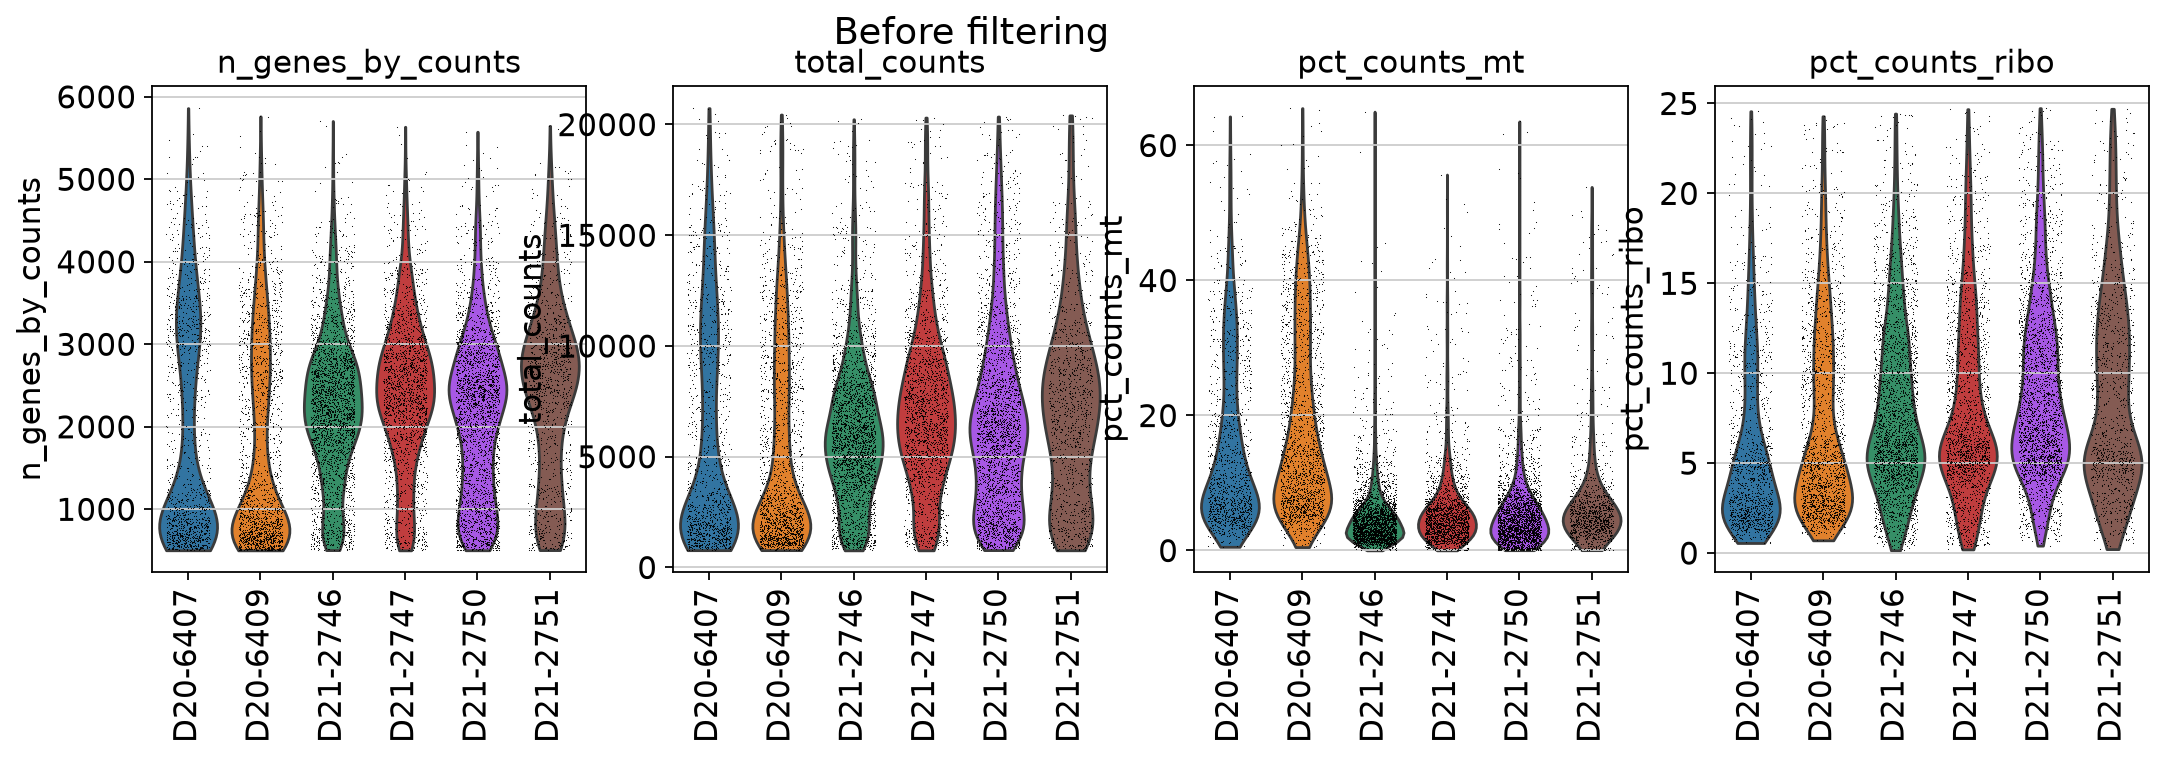

In [6]:
qc_cols = ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo"]
pre.obs["qc"] = np.where(pre.obs["qc_pass"], "kept", "removed")

fig, axes = plt.subplots(1, len(qc_cols), figsize=(4 * len(qc_cols), 4))
for ax, col in zip(axes, qc_cols):
    sc.pl.violin(pre, col, groupby="biosample", jitter=0.3, size=0.5, rotation=90, ax=ax, show=False)
    ax.set_title(col)
fig.suptitle("Before filtering", y=1.02)
scu.save_fig(fig, cfg, "01_qc_violin_before")
plt.show()

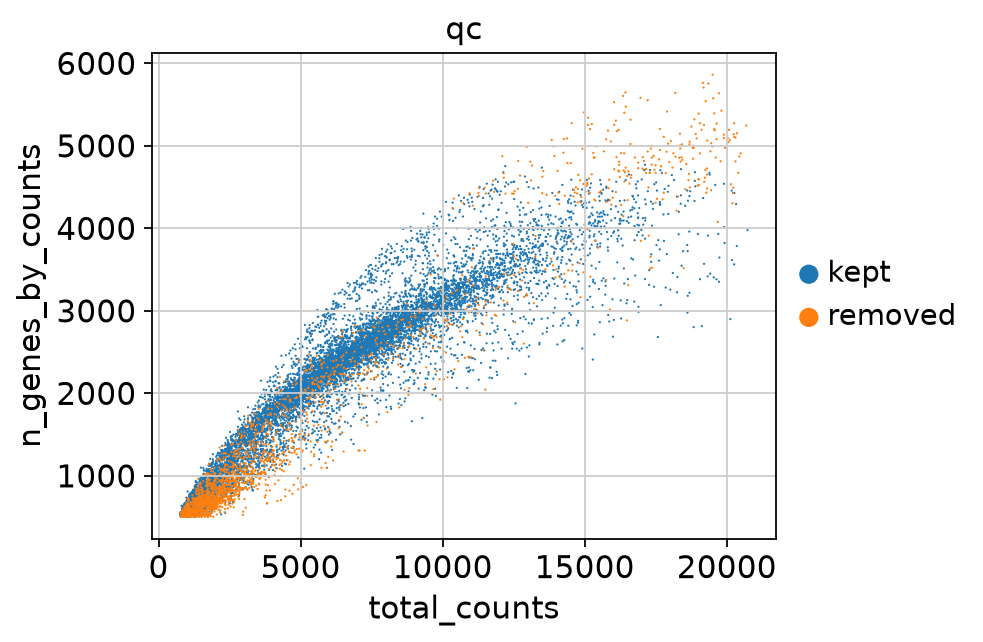

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
sc.pl.scatter(pre, x="total_counts", y="n_genes_by_counts", color="qc", ax=ax, show=False, size=4)
scu.save_fig(fig, cfg, "01_qc_scatter_counts_genes")
plt.show()

### QC bias check: which cells are removed?

If activated or damaged cells (e.g. microglia after cisplatin) were preferentially removed by QC, the downstream
results would under-represent them. Removed cells have no annotation of ours, so the **authors' `MajorCellType`**
(available for every cell) is used. For each cell type: fraction removed per sample and by which filter, tested
with OLS `~ batch + condition` per cell type (types with >= 20 cells in every sample). For microglia, activation
(DAM), homeostatic and immediate-early (IEG) scores of removed vs kept cells.

In [8]:
obs_pre = pre.obs.assign(removed=~pre.obs["qc_pass"])
meta_s = (obs_pre[["biosample", "pathology"]].drop_duplicates().set_index("biosample"))
meta_s.index = meta_s.index.astype(str)
meta_s["condition"] = pd.Categorical(meta_s["pathology"].astype(str).map(cfg["condition_labels"]),
                                     categories=[cfg["reference_condition"]] + [c for c in cfg["condition_labels"].values()
                                                                                if c != cfg["reference_condition"]])
meta_s["batch"] = meta_s.index.str[:3]

n_ct = obs_pre.groupby(["biosample", "MajorCellType"], observed=True).size().unstack(fill_value=0)
frac_removed = obs_pre.groupby(["biosample", "MajorCellType"], observed=True)["removed"].mean().unstack()
frac_removed.index = frac_removed.index.astype(str)
testable = n_ct.columns[(n_ct >= 20).all()]
removal_test = scu.ols_by_column(frac_removed[testable], meta_s, "~ batch + condition").sort_values("pval")
removal_test.index.name = "MajorCellType"
removal_test.to_csv(cfg["paths"]["tables_dir"] / "01_qc_removal_by_celltype_test.tsv", sep="\t")
display(frac_removed.round(3).join(meta_s[["condition", "batch"]]).sort_values(["condition", "batch"]))
removal_test.round(4)

,Astrocyte,Choroid Plexus,Endothelial,Ependymal,Fibroblast,Immune,Microglia,Neuron,OPC,Oligodendrocyte,Pericyte,Progenitor,condition,batch
biosample,,,,,,,,,,,,,,
D20-6407,0.135,0.000,0.083,0.364,NaN,0.378,0.021,0.419,0.145,0.391,0.133,0.211,Control,D20
D21-2746,0.247,0.343,0.114,0.192,0.000,0.327,0.035,0.493,0.107,0.057,0.314,0.263,Control,D21
D21-2747,0.235,0.284,0.151,0.304,0.250,0.323,0.049,0.634,0.176,0.044,0.500,0.194,Control,D21
D20-6409,0.112,0.014,0.086,0.438,0.222,0.353,0.042,0.356,0.090,0.349,0.154,0.182,Chemotherapy,D20
D21-2750,0.232,0.090,0.160,0.600,0.667,0.510,0.120,0.857,0.261,0.038,0.400,0.500,Chemotherapy,D21
D21-2751,0.257,0.087,0.183,0.278,0.625,0.375,0.120,0.917,0.219,0.036,0.200,0.000,Chemotherapy,D21


,mean_Control,mean_Chemotherapy,coef,pval,n_samples,fdr
MajorCellType,,,,,,
Microglia,0.0349,0.0940,0.0591,0.0369,6,0.2948
Oligodendrocyte,0.1639,0.1410,-0.0229,0.0838,6,0.3277
Choroid Plexus,0.2089,0.0638,-0.1452,0.1229,6,0.3277
Neuron,0.5153,0.7101,0.1948,0.1937,6,0.3538
Endothelial,0.1159,0.1430,0.0271,0.2211,6,0.3538
Immune,0.3424,0.4126,0.0702,0.3225,6,0.4300
OPC,0.1423,0.1898,0.0475,0.4108,6,0.4694
Astrocyte,0.2055,0.2001,-0.0054,0.6768,6,0.6768


In [9]:
# Which filter removed the cells: fraction of each type's cells removed by each filter, per condition (pooled)
by_step = (obs_pre.assign(condition=obs_pre["pathology"].astype(str).map(cfg["condition_labels"]))
           .groupby(["MajorCellType", "condition"], observed=True)["qc_fail"]
           .value_counts(normalize=True).unstack(fill_value=0).drop(columns="", errors="ignore"))
by_step = by_step.loc[[t for t in testable if t in by_step.index.get_level_values(0)]]
by_step.round(3)

qc_fail                       max_genes_quantile  max_pct_ribo  mt_outlier
MajorCellType   condition                                                 
Astrocyte       Chemotherapy               0.012         0.000       0.174
                Control                    0.010         0.000       0.208
Choroid Plexus  Chemotherapy               0.000         0.002       0.076
                Control                    0.003         0.011       0.269
Endothelial     Chemotherapy               0.088         0.017       0.038
                Control                    0.066         0.002       0.047
Immune          Chemotherapy               0.000         0.369       0.036
                Control                    0.000         0.302       0.038
Microglia       Chemotherapy               0.002         0.075       0.019
                Control                    0.000         0.034       0.002
Neuron          Chemotherapy               0.017         0.021       0.622
                Control                    0.031         0.022       0.461
OPC             Chemotherapy               0.108         0.000       0.036
                Control                    0.055         0.000       0.079
Oligodendrocyte Chemotherapy               0.003         0.000       0.159
                Control                    0.007         0.001       0.130

In [10]:
# Activation state of removed vs kept microglia (log-normalized copy, microglia only)
mgd = pre[pre.obs["MajorCellType"] == "Microglia"].copy()
sc.pp.normalize_total(mgd, target_sum=qc["target_sum"])
sc.pp.log1p(mgd)
gene_sets = {"DAM": ["Apoe", "Cst7", "Lpl", "Itgax", "Cd68", "Spp1", "Axl", "Cd9", "Tyrobp", "Trem2"],
             "homeostatic": ["P2ry12", "Tmem119", "Cx3cr1", "Sall1", "Hexb", "Csf1r", "Siglech"],
             "IEG": ["Fos", "Jun", "Junb", "Egr1", "Ier2", "Dusp1", "Zfp36", "Hspa1a"]}
for name, genes in gene_sets.items():
    sc.tl.score_genes(mgd, [g for g in genes if g in mgd.var_names], score_name=name, random_state=0)
mgd.obs["status"] = np.where(mgd.obs["qc_pass"], "kept", "removed")
mgd.obs["condition"] = mgd.obs["pathology"].astype(str).map(cfg["condition_labels"])
act = (mgd.obs.groupby(["condition", "biosample", "status"], observed=True)[list(gene_sets)].median()
       .unstack("status"))
act.columns = [f"{s}_{st}" for s, st in act.columns]
del mgd
gc.collect()
act.round(3)

DAM_kept  DAM_removed  homeostatic_kept  \
condition    biosample                                            
Chemotherapy D20-6409      0.785        0.840             1.700   
             D21-2750      0.914        0.898             1.894   
             D21-2751      0.874        0.996             1.910   
Control      D20-6407      0.791        0.779             1.810   
             D21-2746      0.832        0.961             1.815   
             D21-2747      0.835        0.884             1.856   

                        homeostatic_removed  IEG_kept  IEG_removed  
condition    biosample                                              
Chemotherapy D20-6409                 1.515     1.761        1.380  
             D21-2750                 1.627     1.876        1.637  
             D21-2751                 1.780     1.891        1.580  
Control      D20-6407                 1.586     1.682        1.057  
             D21-2746                 1.564     1.806        1.238  
             D21-2747                 1.625     1.824        1.350

## 3. Merge kept cells, filter genes, keep raw counts

In [11]:
adata = pre[pre.obs["qc_pass"]].copy()
del pre
gc.collect()

n_genes_before = adata.n_vars
sc.pp.filter_genes(adata, min_cells=qc["min_cells"])
print(f"genes: {n_genes_before} -> {adata.n_vars} (min_cells={qc['min_cells']})")

# Condition labels applied once, here (PN -> Control, CN -> Chemotherapy)
adata.obs["condition"] = pd.Categorical(
    adata.obs["pathology"].astype(str).map(cfg["condition_labels"]),
    categories=[cfg["reference_condition"]] + [c for c in cfg["condition_labels"].values()
                                               if c != cfg["reference_condition"]])
adata.obs = adata.obs.drop(columns=["qc_pass", "qc", "qc_fail"])
for col in adata.obs.select_dtypes("category"):
    adata.obs[col] = adata.obs[col].cat.remove_unused_categories()
adata

genes: 32285 -> 19941 (min_cells=3)


AnnData object with n_obs × n_vars = 9832 × 19941
    obs: 'biosample', 'pathology', 'batch', 'doublet_score', 'predicted_doublet', 'MajorCellType', 'orig_celltype', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'condition'
    var: 'mt', 'ribo', 'hb', 'n_cells'
    uns: 'biosample_colors', 'qc_colors'
    layers: None (.X)

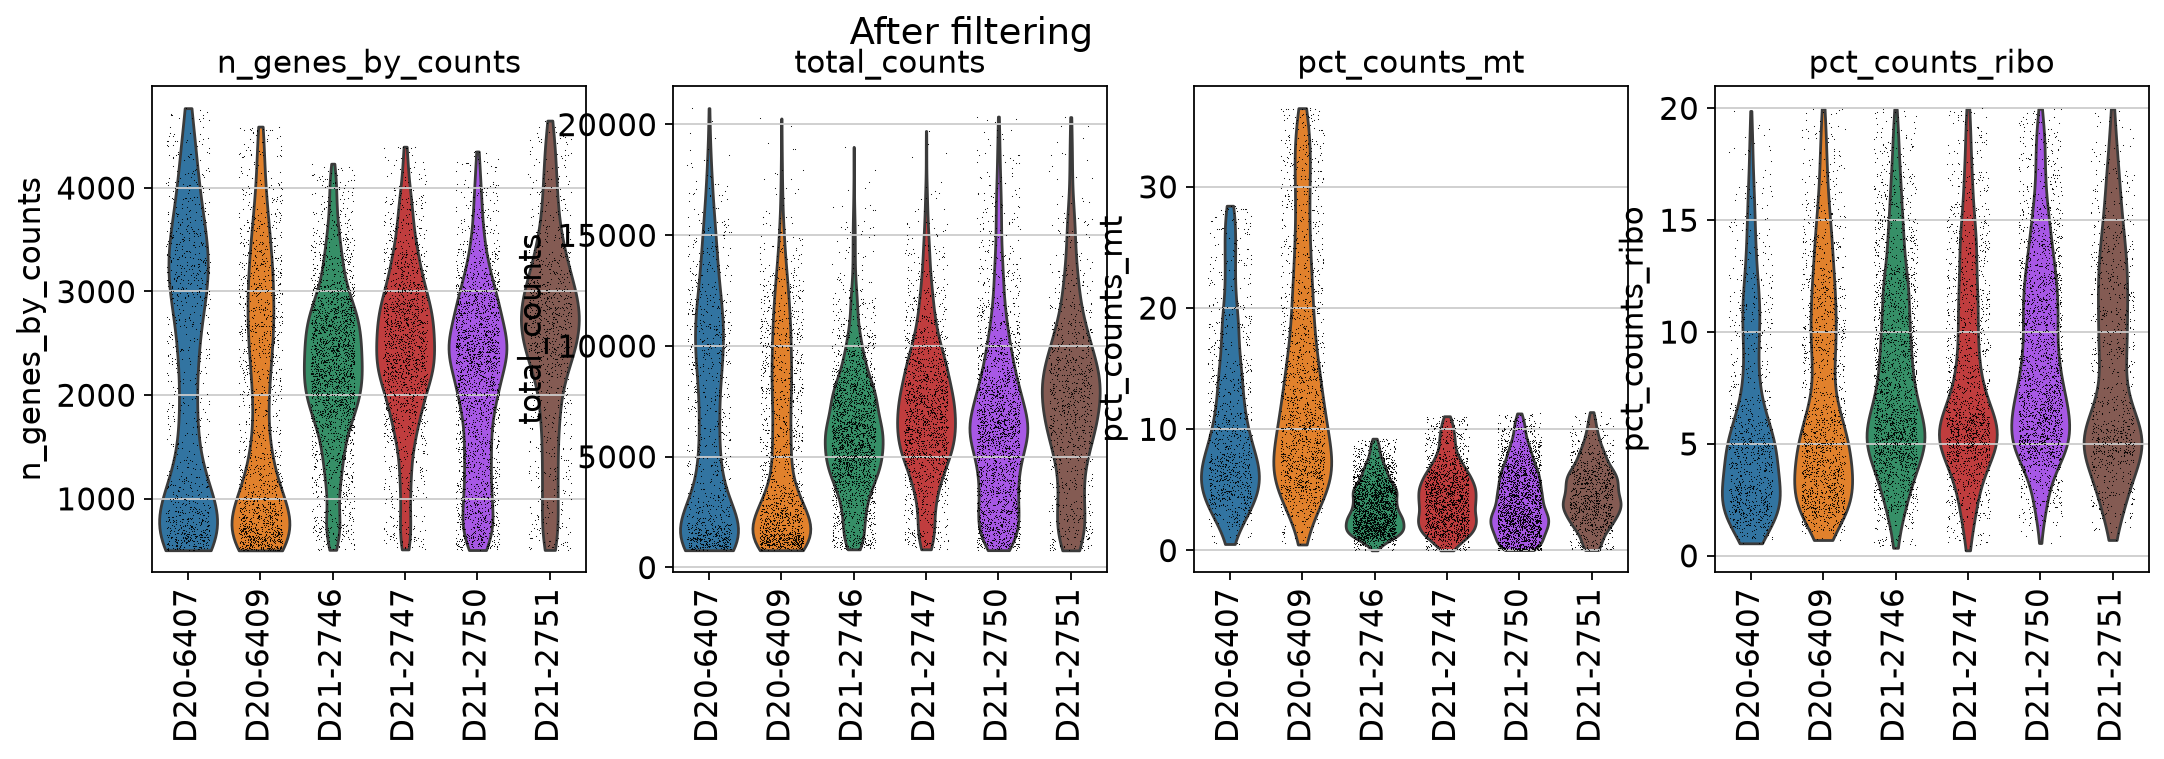

In [12]:
fig, axes = plt.subplots(1, len(qc_cols), figsize=(4 * len(qc_cols), 4))
for ax, col in zip(axes, qc_cols):
    sc.pl.violin(adata, col, groupby="biosample", jitter=0.3, size=0.5, rotation=90, ax=ax, show=False)
    ax.set_title(col)
fig.suptitle("After filtering", y=1.02)
scu.save_fig(fig, cfg, "01_qc_violin_after")
plt.show()

In [13]:
summary = (adata.obs.groupby(["condition", "biosample"], observed=True)
           .agg(cells=("n_genes_by_counts", "size"),
                median_genes=("n_genes_by_counts", "median"),
                median_counts=("total_counts", "median"),
                median_pct_mt=("pct_counts_mt", "median")))
summary

cells  median_genes  median_counts  median_pct_mt
condition    biosample                                                   
Control      D20-6407     988        2136.5         5417.5       8.733002
             D21-2746    2384        2301.0         5930.5       3.484172
             D21-2747    1650        2497.5         6948.0       4.239852
Chemotherapy D20-6409    1591        1510.0         3837.0      11.926605
             D21-2750    2312        2275.5         6173.0       3.817765
             D21-2751     907        2674.0         7638.0       4.562738

## 4. Normalize and save

In [14]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=qc["target_sum"])
sc.pp.log1p(adata)

out_h5ad = cfg["paths"]["results_dir"] / "01_qc.h5ad"
adata.write_h5ad(out_h5ad, compression="gzip")

out_table = cfg["paths"]["tables_dir"] / "01_qc_cell_counts.tsv"
counts_table.join(summary.reset_index("condition").drop(columns="cells")).to_csv(out_table, sep="\t")
print("wrote", out_h5ad, "and", out_table)
print(adata)

wrote /home/arlindo/github/single-cell-rna-seq/single_cell_notebook/results/01_qc.h5ad and /home/arlindo/github/single-cell-rna-seq/single_cell_notebook/results/tables/01_qc_cell_counts.tsv
AnnData object with n_obs × n_vars = 9832 × 19941
    obs: 'biosample', 'pathology', 'batch', 'doublet_score', 'predicted_doublet', 'MajorCellType', 'orig_celltype', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'condition'
    var: 'mt', 'ribo', 'hb', 'n_cells'
    uns: 'biosample_colors', 'qc_colors', 'log1p'
    layers: None (.X), 'counts'


In [15]:
del adata
gc.collect()

17394